# Border-effect sanity checks: image mask vs. count-derived border

One row per sample, three columns:

1. **Image + mask/spot contours** -- the tissue image (H&E for Visium, ssDNA
   for STOmics), with the tissue mask (lime) and the count/grid-derived
   spot-occupancy footprint (pink) overlaid. The lime mask is now exactly
   the same source used for calculations: Space Ranger's own `in_tissue`
   for Visium, the counts-independent image-only mask for STOmics (both
   also column 3's mask, just at column 1's own pooled display resolution).
2. **Counts + border/elbow/BLADE** -- raw total counts in grid space, with
   the spot-occupancy footprint (pink), the bosperrus piecewise-linear elbow
   (blue), and the BLADE erosion-layer threshold (orange). Both are fit per
   spatially-connected component (e.g. a TMA's individual cores) and
   combined into one whole-sample raster.
3. **RAW counts outside the image mask** -- unlike columns 1/2 (which only
   ever see the filtered/in-tissue-called spot population), this uses the
   RAW, whole-capture-area feature-barcode matrix, so it can actually show
   counts beyond wherever Space Ranger/SAW already drew their own tissue
   boundary. Mask = Space Ranger's own `in_tissue` for Visium (grid space,
   matching column 2), the existing counts-independent image-only mask for
   STOmics (pixel space, pooled to 10um for speed). Downscaled on purpose
   (8um Visium, 10um STOmics) since this is a visual check, not the
   production fit -- see `results/exploratory/raw_pooled_diffusion/` for
   the full-resolution numbers.

Thresholds come from `src/utils/border_fit.py::get_or_compute_component_fit`
(cached, shared with `ST.ipynb`).

In [1]:
import gc
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import ndimage

sys.path.insert(0, str((Path("..") / "src" / "utils").resolve()))
import visium_hd
from border_fit import ALL_SAMPLES, FIT_PALETTE, get_grid_components, get_or_compute_component_fit, grid_border_distance

/home/woody/iwbn/iwbn007h/bosperrus/truncated_graphs/.pixi/envs/default/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/woody/iwbn/iwbn007h/bosperrus/truncated_graphs/.pixi/envs/default/lib/python3.12/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


In [2]:
# --- Computational parameters ---
MARGIN_FRAC = 0.05       # crop margin around qualifying spots, as a fraction of their extent
TARGET_POOL_SIZE = 800   # target long-edge resolution (px) for mask/spot pooling

In [3]:
# --- Plotting parameters ---
N_SAMPLES = len(ALL_SAMPLES)

BSPBLUE = FIT_PALETTE["Piecewise Linear Fit"]
BLADE_ORANGE = "orange"
IMAGE_MASK_COLOR = "#39FF14"   # lime
SPOT_MASK_COLOR = "#FF1493"    # deep pink

PAD = 5        # zero-pad (grid cells) so column 2's contours close at the array edge
POOL_PAD = 5   # zero-pad (pooled cells) so columns 1/3's contours close at the crop edge

## Build the figure, one row per sample

In [4]:
import h5py
from scipy.sparse import csc_matrix
import pandas as pd

# Column 3 now uses RAW (unfiltered, whole-capture-area) data and the same
# counts-independent/in_tissue mask convention as src/utils/raw_diffusion.py --
# duplicated here (not imported) so editing this notebook can never affect
# that script's currently-running SLURM jobs. Downscaled on purpose (per-axis
# factors below) since this is a visual sanity check, not the production fit.

VISIUM_RAW_OUTS = {
    "Pat1": "/home/woody/iwbn/iwbn007h/10x_data_3_4/Pat1/Pr416_Pat1/outs",
    "Pat2": "/home/woody/iwbn/iwbn007h/10x_data/Pr416_Pat2/outs",
    "Pat3": "/home/woody/iwbn/iwbn007h/10x_data_3_4/Pat3/Pr416_Pat3/outs",
    "Pat4": "/home/woody/iwbn/iwbn007h/10x_data_3_4/Pat4/Pr416_Pat4/outs",
    "breast_cancer": "/home/woody/iwbn/iwbn007h/visium_hd_demo_data/Visium_HD_11mm_Human_Breast_Cancer",
    "pancreas": "/home/woody/iwbn/iwbn007h/visium_hd_demo_data/Visium_HD_11mm_Human_Pancreas",
    "colon_cancer_ff": "/home/woody/iwbn/iwbn007h/visium_hd_demo_data/Visium_HD_11mm_Human_Colon_Cancer_Fresh_Frozen",
    "breast_cancer_tma": "/home/woody/iwbn/iwbn007h/visium_hd_demo_data/Visium_HD_11mm_Human_Breast_Cancer_TMA",
}
STOMICS_RAW_GEF = {
    "A02991D1": "/home/vault/iwbn/shared/stomics_data_analysis/Patient_1_out/271025_realigned/outs/feature_expression/A02991D1.raw.gef",
    "A02994C6": "/home/vault/iwbn/shared/stomics_data_analysis/Patient_2_out/271025_realigned/outs/feature_expression/A02994C6.raw.gef",
    "Y01087DD": "/home/vault/iwbn/shared/stomics_data_analysis/Patient_3_out/300626_2nd_exp/outs/feature_expression/Y01087DD.raw.gef",
    "Y01084J8": "/home/vault/iwbn/shared/stomics_data_analysis/Patient_4_out/300626_2nd_exp/outs/feature_expression/Y01084J8.raw.gef",
}
STOMICS_MASK_NPZ = "/home/woody/iwbn/iwbn007h/spatial_data/stomics/{name}_ssDNA_tissue_mask_final_native.npz"
STOMICS_REBIN_FACTOR = 20  # bin1 (0.5um) -> 10um, matching this project's established bin20 convention


def load_raw_outside_visium(sample):
    """Space Ranger's own pre-binned 8um raw matrix (whole capture area, not
    just filtered/in-tissue) -- downscaled "for free" versus native 2um, no
    manual rebinning needed. Mask = Space Ranger's own tissue_positions.parquet
    in_tissue column (not the image-derived segment_tissue_from_rgb mask),
    rasterized directly onto the array_row/array_col grid -- plotted in grid
    space (matching column 2's convention) so no pixel-space alignment is
    needed at all."""
    bin_dir = Path(VISIUM_RAW_OUTS[sample]) / "binned_outputs" / "square_008um"
    with h5py.File(bin_dir / "raw_feature_bc_matrix.h5") as f:
        mat = csc_matrix((f["matrix"]["data"][:], f["matrix"]["indices"][:], f["matrix"]["indptr"][:]),
                          shape=tuple(f["matrix"]["shape"][:]))
        barcodes = np.array([b.decode() for b in f["matrix"]["barcodes"][:]])
    n_counts = np.asarray(mat.sum(axis=0)).ravel()

    positions = pd.read_parquet(bin_dir / "spatial" / "tissue_positions.parquet").set_index("barcode").loc[barcodes]
    array_row = positions["array_row"].to_numpy()
    array_col = positions["array_col"].to_numpy()
    in_tissue = positions["in_tissue"].to_numpy().astype(bool)

    grid = np.zeros((array_row.max() + 1, array_col.max() + 1), dtype=bool)
    grid[array_row[in_tissue], array_col[in_tissue]] = True
    signed_dist = ndimage.distance_transform_edt(~grid) - ndimage.distance_transform_edt(grid)
    outside = signed_dist[array_row, array_col] > 0
    return array_col, array_row, n_counts, outside, grid


def load_raw_outside_stomics(sample):
    """raw.gef bin1 (whole chip, pre-tissuecut), rebinned to 10um by floor
    division (matches SAW's own binning convention -- verified exactly
    against the existing bin20_1.0.h5ad earlier this session). Mask = the
    same counts-independent image-only mask already used elsewhere, pooled
    down by the same factor before the distance transform (native-resolution
    distance_transform_edt on this ~484M-pixel mask needs ~7GB, unnecessary
    for a downscaled visual check)."""
    with h5py.File(STOMICS_RAW_GEF[sample], "r") as f:
        expr = f["geneExp"]["bin1"]["expression"][:]
    x, y, count = expr["x"].astype(np.int64), expr["y"].astype(np.int64), expr["count"].astype(np.int64)
    xb, yb = x // STOMICS_REBIN_FACTOR, y // STOMICS_REBIN_FACTOR
    xy = xb * (yb.max() + 1) + yb
    order = np.argsort(xy, kind="stable")
    xy_sorted, count_sorted = xy[order], count[order]
    xb_sorted, yb_sorted = xb[order], yb[order]
    change = np.empty(len(xy_sorted), dtype=bool)
    change[0] = True
    change[1:] = xy_sorted[1:] != xy_sorted[:-1]
    group_start = np.flatnonzero(change)
    n_counts = np.add.reduceat(count_sorted, group_start)
    px, py = xb_sorted[group_start], yb_sorted[group_start]

    mask = np.load(STOMICS_MASK_NPZ.format(name=sample))["mask"]
    mask_pooled = visium_hd.block_or_pool(mask, STOMICS_REBIN_FACTOR)
    px = np.clip(px, 0, mask_pooled.shape[1] - 1)
    py = np.clip(py, 0, mask_pooled.shape[0] - 1)
    signed_dist = ndimage.distance_transform_edt(~mask_pooled) - ndimage.distance_transform_edt(mask_pooled)
    outside = signed_dist[py, px] > 0
    return px, py, n_counts, outside, mask_pooled


def load_raw_outside(loader_type, sample):
    if loader_type == "visium":
        return load_raw_outside_visium(sample)
    return load_raw_outside_stomics(sample)

In [5]:
def process_sample_row(fig, axes_row, i):
    sample = ALL_SAMPLES["name"].iloc[i]
    loader_type = ALL_SAMPLES["loader"].iloc[i]
    h5ad_path = ALL_SAMPLES["h5ad_path"].iloc[i]
    dataset_type = ALL_SAMPLES["dataset_type"].iloc[i]
    bin_size_um = ALL_SAMPLES["bin_size_um"].iloc[i]
    print("reading", sample)

    n_counts, array_row, array_col, spatial = visium_hd.load_counts_and_coords(loader_type, h5ad_path)

    # Fit bosperrus/BLADE per spatially-connected component (e.g. a TMA's
    # cores), then combine into whole-sample arrays for a shared crop/context.
    components = get_grid_components(array_row, array_col)
    dist_to_border = np.full(len(array_row), np.nan)
    in_bsp_buffer = np.zeros(len(array_row), dtype=bool)
    component_label = np.full(len(array_row), -1)
    blade_thresh_by_component = {}
    for component_rank, member_mask, component_size in components:
        fit = get_or_compute_component_fit(sample, component_rank, component_size, h5ad_path, bin_size_um,
                                            array_row[member_mask], array_col[member_mask], n_counts[member_mask])
        dist_to_border[member_mask] = grid_border_distance(array_row[member_mask], array_col[member_mask])
        in_bsp_buffer[member_mask] = dist_to_border[member_mask] <= fit["bsp_thresh"]
        component_label[member_mask] = component_rank
        blade_thresh_by_component[component_rank] = fit["blade_thresh"]

    qual = component_label >= 0  # spots in a qualifying component; everything below is restricted to this
    qual_row, qual_col = array_row[qual], array_col[qual]

    # Orientation between grid axes and pixel axes isn't a fixed convention --
    # it varies per sample/axis, so measure it from the data.
    spatial_qual = spatial[qual].astype(np.float64)
    flip_col_axis = np.corrcoef(qual_col, spatial_qual[:, 0])[0, 1] < 0
    flip_row_axis = np.corrcoef(qual_row, spatial_qual[:, 1])[0, 1] > 0

    # --- grid-space (column 2): occupancy, bosperrus elbow, BLADE erosion-depth
    occupancy, row_off, col_off = visium_hd.rasterize_grid(qual_row, qual_col, np.ones(len(qual_row)), fill=0.0)
    occupancy_bool = occupancy > 0
    # 1px-pad before the taxicab transform so edge-touching cells read as
    # layer 1, matching peel_sweep's own binary_erosion(border_value=0).
    erosion_depth = ndimage.distance_transform_cdt(np.pad(occupancy_bool, 1, constant_values=False), metric="taxicab")[1:-1, 1:-1]
    erosion_depth_at_spot = erosion_depth[qual_row - row_off, qual_col - col_off]
    qual_component_label = component_label[qual]
    thresh_lut = np.full(max(blade_thresh_by_component, default=-1) + 1, np.inf)
    for rank, thresh in blade_thresh_by_component.items():
        thresh_lut[rank] = thresh
    in_blade_buffer_qual = erosion_depth_at_spot <= thresh_lut[qual_component_label]

    bsp_grid, _, _ = visium_hd.rasterize_grid(qual_row, qual_col, in_bsp_buffer[qual].astype(float), fill=0.0)
    blade_grid, _, _ = visium_hd.rasterize_grid(qual_row, qual_col, in_blade_buffer_qual.astype(float), fill=0.0)
    del erosion_depth, erosion_depth_at_spot, thresh_lut

    # Pad so contour() can close the boundary at the raster's own (always tight-fit) edge.
    occupancy_bool = np.pad(occupancy_bool, PAD, constant_values=False)
    bsp_grid = np.pad(bsp_grid, PAD, constant_values=0.0)
    blade_grid = np.pad(blade_grid, PAD, constant_values=0.0)
    row_off, col_off = row_off - PAD, col_off - PAD
    del occupancy

    # --- pixel-space: image mask + crop bbox (qualifying spots only) -- column 1 only now.
    # Mask source now EXACTLY matches what raw_diffusion.py/ST.ipynb use for calculations:
    # STOmics keeps the same counts-independent {name}_ssDNA_tissue_mask_final_native.npz
    # (load_image_mask already used this -- just pooled here for display). Visium switches
    # from the old Otsu-based segment_tissue_from_rgb mask to Space Ranger's own in_tissue
    # (same source as column 3's Visium branch, at the same 8um resolution -- a downscaled
    # check, but the identical tissue-boundary definition, not a different mask).
    if loader_type == "visium":
        _, pixel_scale = visium_hd.load_visium_hires_image(h5ad_path, sample)
    else:
        pixel_scale = 1.0
    coords_rc = np.stack([spatial[:, 1] * pixel_scale, spatial[:, 0] * pixel_scale], axis=1)

    row_min, row_max = coords_rc[qual, 0].min(), coords_rc[qual, 0].max()
    col_min, col_max = coords_rc[qual, 1].min(), coords_rc[qual, 1].max()
    margin_row, margin_col = (row_max - row_min) * MARGIN_FRAC, (col_max - col_min) * MARGIN_FRAC
    row0, col0 = max(0, int(row_min - margin_row)), max(0, int(col_min - margin_col))
    row1_want, col1_want = int(row_max + margin_row), int(col_max + margin_col)

    image_crop = visium_hd.load_cropped_image(loader_type, h5ad_path, sample, row0, row1_want, col0, col1_want)
    h, w = image_crop.shape[:2]  # actual crop size (numpy slicing already clipped to bounds)

    factor = max(1, round(h / TARGET_POOL_SIZE))
    h_pool, w_pool = h // factor, w // factor

    if loader_type == "visium":
        bin_dir = Path(VISIUM_RAW_OUTS[sample]) / "binned_outputs" / "square_008um"
        positions = pd.read_parquet(bin_dir / "spatial" / "tissue_positions.parquet")
        in_tissue = positions["in_tissue"].to_numpy().astype(bool)
        in_tissue_rc = np.stack([
            positions["pxl_row_in_fullres"].to_numpy()[in_tissue] * pixel_scale,
            positions["pxl_col_in_fullres"].to_numpy()[in_tissue] * pixel_scale,
        ], axis=1)
        mask_hist, _, _ = np.histogram2d(
            in_tissue_rc[:, 0] - row0, in_tissue_rc[:, 1] - col0,
            bins=[h_pool, w_pool], range=[[0, h], [0, w]],
        )
        mask_pooled = ndimage.binary_closing(mask_hist > 0, structure=np.ones((3, 3))).astype(float)
        del positions, in_tissue, in_tissue_rc, mask_hist
    else:
        mask, _ = visium_hd.load_image_mask(loader_type, h5ad_path, sample)
        mask_crop = mask[row0:row0 + h, col0:col0 + w]
        mask_pooled = visium_hd.block_or_pool(mask_crop, factor).astype(float)
        del mask, mask_crop

    # Bin directly at the pooled resolution (raster-then-pool aliases into moire/crosshatch).
    spot_hist, _, _ = np.histogram2d(
        coords_rc[qual, 0] - row0, coords_rc[qual, 1] - col0,
        bins=[h_pool, w_pool], range=[[0, h], [0, w]],
    )
    spot_pooled = ndimage.binary_closing(spot_hist > 0, structure=np.ones((3, 3))).astype(float)
    del spot_hist

    dy = h / (h_pool - 1) if h_pool > 1 else 1.0
    dx = w / (w_pool - 1) if w_pool > 1 else 1.0
    mask_pooled = np.pad(mask_pooled, POOL_PAD, constant_values=0.0)
    spot_pooled = np.pad(spot_pooled, POOL_PAD, constant_values=0.0)
    pool_y = np.linspace(-POOL_PAD * dy, h + POOL_PAD * dy, h_pool + 2 * POOL_PAD)
    pool_x = np.linspace(-POOL_PAD * dx, w + POOL_PAD * dx, w_pool + 2 * POOL_PAD)

    # === Column 1: raw image + both contours ===
    ax = axes_row[0]
    if image_crop.ndim == 2:
        ax.imshow(image_crop, cmap="gray", vmin=0, vmax=np.percentile(image_crop, 99.5))
    else:
        ax.imshow(image_crop)
    # in_tissue and the spot footprint are usually near-identical (verified: e.g. Pat3's
    # pooled cell counts differ by <2%, connected-component sizes match almost exactly) --
    # solid-on-solid contours drawn this close overlap almost perfectly, so whichever is
    # drawn second visually erases the first wherever they agree, which looks like "the
    # mask is missing" even though it isn't. Dashing the mask line lets the spot line show
    # through the gaps, so both stay visible even where they coincide.
    ax.contour(pool_x, pool_y, mask_pooled, levels=[0.5], colors=[IMAGE_MASK_COLOR], linewidths=1.8, linestyles="--")
    ax.contour(pool_x, pool_y, spot_pooled, levels=[0.5], colors=[SPOT_MASK_COLOR], linewidths=1.2)
    ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(f"{sample} ({dataset_type}): image + mask/spot contours", fontsize=9)
    if i == 0:
        col1_handles = [
            Line2D([0], [0], color=IMAGE_MASK_COLOR, lw=1.8, ls="--", label="tissue mask (same source as calculations)"),
            Line2D([0], [0], color=SPOT_MASK_COLOR, lw=1.2, label="spot-derived footprint"),
        ]
        ax.legend(handles=col1_handles, loc="lower center", bbox_to_anchor=(0.5, 1.08),
                  ncol=2, fontsize=8, frameon=False)
    del image_crop, spot_pooled, mask_pooled, pool_x, pool_y, coords_rc

    # === Column 2: counts + occupancy + elbow + BLADE ===
    ax = axes_row[1]
    x_coords = col_off + np.arange(occupancy_bool.shape[1])
    y_coords = row_off + np.arange(occupancy_bool.shape[0])
    ax.scatter(qual_col, qual_row, c=n_counts[qual], cmap="gray", s=1, alpha=0.5, rasterized=True)
    ax.contour(x_coords, y_coords, bsp_grid, levels=[0.5], colors=[BSPBLUE], linewidths=1.2)
    ax.contour(x_coords, y_coords, blade_grid, levels=[0.5], colors=[BLADE_ORANGE], linewidths=1.2)
    ax.contour(x_coords, y_coords, occupancy_bool.astype(float), levels=[0.5], colors=[SPOT_MASK_COLOR], linewidths=0.8)
    ax.set_aspect("equal")
    x_pad, y_pad = (x_coords[-1] - x_coords[0]) * 0.06, (y_coords[-1] - y_coords[0]) * 0.06
    if flip_col_axis:
        ax.set_xlim(x_coords[-1] + x_pad, x_coords[0] - x_pad)
    else:
        ax.set_xlim(x_coords[0] - x_pad, x_coords[-1] + x_pad)
    if flip_row_axis:
        ax.set_ylim(y_coords[-1] + y_pad, y_coords[0] - y_pad)
    else:
        ax.set_ylim(y_coords[0] - y_pad, y_coords[-1] + y_pad)
    ax.axis("off")
    ax.set_title(f"{sample}: counts + border/elbow/BLADE", fontsize=9)
    if i == 0:
        col2_handles = [
            Line2D([0], [0], color=BSPBLUE, lw=1.5, label="bosperrus elbow"),
            Line2D([0], [0], color=BLADE_ORANGE, lw=1.5, label="BLADE threshold"),
            Line2D([0], [0], color=SPOT_MASK_COLOR, lw=1.5, label="spot-derived footprint"),
        ]
        ax.legend(handles=col2_handles, loc="lower center", bbox_to_anchor=(0.5, 1.08),
                  ncol=3, fontsize=8, frameon=False)
    del occupancy_bool, bsp_grid, blade_grid, n_counts, spatial, dist_to_border

    # === Column 3: RAW counts outside the image mask (whole capture area, not just filtered/in-tissue) ===
    ax = axes_row[2]
    raw_x, raw_y, raw_counts, raw_outside, raw_mask = load_raw_outside(loader_type, sample)
    ax.contour(np.arange(raw_mask.shape[1]), np.arange(raw_mask.shape[0]), raw_mask.astype(float),
               levels=[0.5], colors=["black"], linewidths=0.8)
    sca = ax.scatter(raw_x[raw_outside], raw_y[raw_outside], c=raw_counts[raw_outside],
                      cmap="viridis", s=2, rasterized=True)
    fig.colorbar(sca, ax=ax, shrink=0.6, pad=0.02, label="n_counts (raw)")
    ax.set_aspect("equal")
    if loader_type == "visium":
        # grid space, matching column 2's own measured orientation. NOTE: this is
        # the same flip_col_axis/flip_row_axis pair column 2 uses, but column 2's
        # own row-flip branches are the opposite way around from what looks like
        # the "matching" structure here -- verified empirically (all 8 Visium
        # samples were flipped up-down, one also left-right) that the row
        # condition needed inverting relative to the first attempt below.
        ax.set_xlim(*((raw_mask.shape[1], 0) if flip_col_axis else (0, raw_mask.shape[1])))
        ax.set_ylim(*((raw_mask.shape[0], 0) if flip_row_axis else (0, raw_mask.shape[0])))
        mask_kind = "in_tissue grid, 8um"
    else:
        # pixel space (mask's own coordinate system, pixel_scale=1.0) -- standard image orientation
        ax.set_xlim(0, raw_mask.shape[1]); ax.set_ylim(raw_mask.shape[0], 0)
        mask_kind = "image mask, 10um"
    ax.axis("off")
    ax.set_title(f"{sample}: RAW counts outside image mask ({mask_kind})", fontsize=9)
    del raw_x, raw_y, raw_counts, raw_outside, raw_mask

    gc.collect()

reading breast_cancer
reading pancreas
reading colon_cancer_ff
reading breast_cancer_tma
reading Pat1
reading Pat2
reading Pat3
reading Pat4
reading A02991D1
reading A02994C6
reading Y01087DD
reading Y01084J8


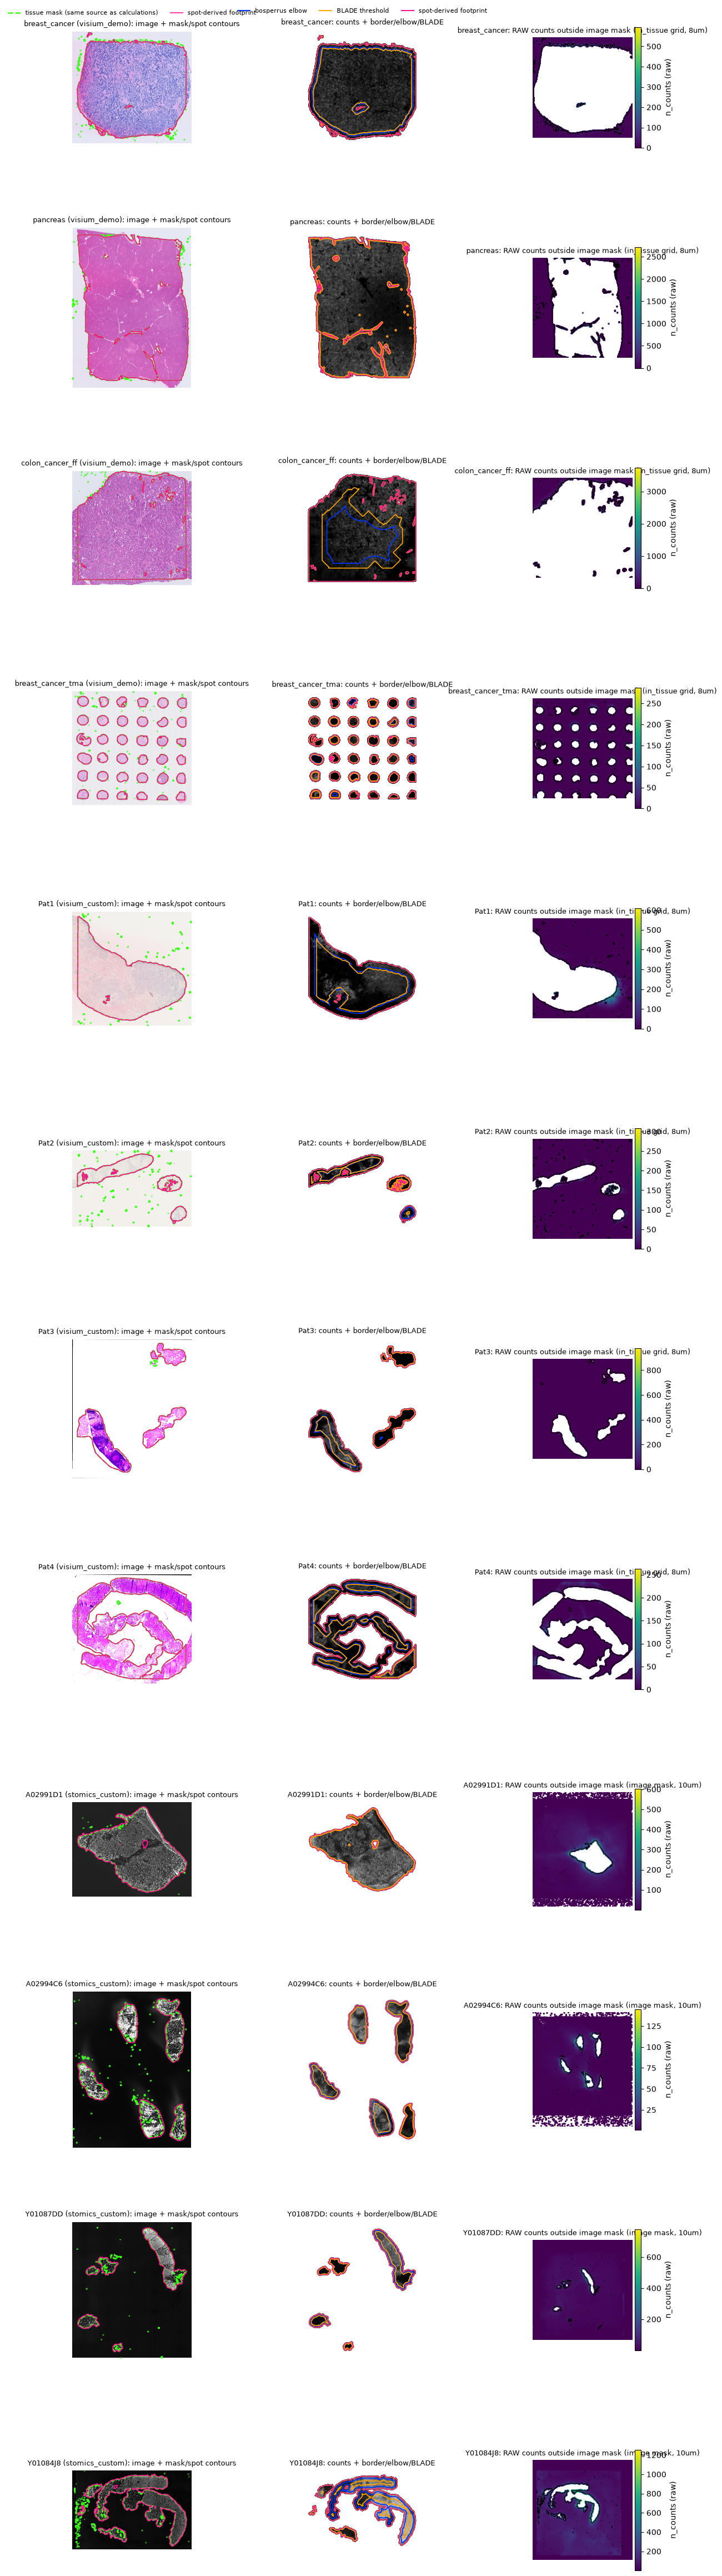

In [6]:
fig, axes = plt.subplots(N_SAMPLES, 3, figsize=(12, 4 * N_SAMPLES))
for i in range(N_SAMPLES):
    process_sample_row(fig, axes[i], i)
plt.tight_layout()
plt.show()